# Interpolate 3D model
This section explains how to query a 3D velocity model, interpolate values, and visualize the results.<br>
Written by Andrea C. Riaño.<br> 
andrea.riano@bsc.es

---
### How to use this notebook

1. Make sure to have python 3.6 or later installed in your PC.
2. Install the required dependencies executing the first cell of this notebook.

In [1]:
import os
import sys
import shutil
sys.path.append("VelocityModel_utils/") 
import subprocess
import numpy as np
import VelocityModel_utils

# List of required libraries
required_libraries = [
    "cartopy", "folium", "joblib", "matplotlib", "netCDF4", 
    "numpy", "pandas", "psutil", "pyproj", "scipy", 
    "shapely", "simplekml", "tqdm"
]

# Check if libraries are installed
missing_libraries = []
for lib in required_libraries:
    try:
        __import__(lib)
    except ImportError:
        missing_libraries.append(lib)

# Install missing libraries
if missing_libraries:
    print(f"The following dependencies are missing: {', '.join(missing_libraries)}")
    print("Installing missing dependencies quietly...")
    try:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-r", "requirements.txt", "-q"],
            stdout=subprocess.DEVNULL,  # Suppresses standard output
            stderr=subprocess.DEVNULL   # Suppresses standard error
        )
        print("Missing dependencies installed successfully.")
    except subprocess.CalledProcessError as e:
        print(f"An error occurred during installation: {e}")
else:
    print("All required dependencies are already installed.")

import pandas as pd

All required dependencies are already installed.


---
## Important concepts and input parameters description
### Cybershake domain's corners conventions

     (North ↑)
         ^ 
         |
        C2 ------------------- C3
         |                     |  
         |       Model         |  
         |       Domain        |  
         |                     |  
        C1 ------------------- C4 --> (East →)

### Domain rotation
<img src="VelocityModel_utils/modelrot.png" width="350">

### Path to the Input Data Folder and Velocity Model File
- **`input_folder`** = `Example_3DVelocityModel/inputData/`  
  Path to the folder containing the input data.  
- **`vm_file`** = `cvms5_1d_depth_socal.nc`  
  The velocity model (VM) file containing 3D velocity model data used for interpolation.  
  Possible input formats: `csv`, `txt`, `nc`, `json`.  
- **`velocity_units`** = `km/s`  
  Units for velocity values in the input velocity model (vm_file). 
- **`density_units`** = `kg/m³`  
  Units for density values in the input velocity model (vm_file).  

### Anelastic or Elastic Model  
- **`is_anelastic`** = `False`  
  Set to `False` for an elastic model (Vp, Vs, and Rho only).  
  Set to `True` for an anelastic model.  

### Geographic Coordinates of the Model Domain  
- **`model_lon`** = `-119.38`  
  Longitude of the domain's C1 corner (degrees).  
- **`model_lat`** = `34.13`  
  Latitude of the domain's C1 corner (degrees).  

### Model Domain Dimensions (in Kilometers)  
- **`x_length`** = `200`  
  Length along the local X-axis, which is the distance from C1 to C4 and is equal to the distance from C2 to C3. 
- **`y_length`** = `120`  
  Length along the local Y-axis, which is the distance from C1 to C2 and is equal to the distance from C4 to C3.  
- **`z_length`** = `30`  
  Depth of the model. 

### Model Rotation  
- **`model_rot`** = `-90`  
  Rotation of the simulation domain.  
  A value of `-90` means the model is rotated 90° counterclockwise around C1, meaning C2 moves above C1. 

### Grid Configuration  
- **`grid_spacing`** = `1`  
  Distance between each grid point in the model (in km).  

### Model Region  
- **`region`** = `SouthernCalifornia`  
  This refers to the name of the region, which is used when naming the output files.  

### Variables and Plot Configuration  
- **`variable_name`** = `Vp`  
  Variable to plot. Options: `'Vp'`, `'Vs'`, `'Rho'`. If `is_anelastic=True`, also `'Qp'` and `'Qs'`.  
- **`plane_type`** = `XZ`  
  Plane to plot (`XZ` or `YZ` at index in the local Y or X direction, respectively).  
- **`index`** = `10`  
  Index location for the plane to plot.   
- **`index_z`** = `0`  
  XY surface is plotted by default at the depth corresponding to this index.  

### Dynamic Map Configuration  
- **`Domain_dynmap`** = `True`  
  When Domain_dynmap is set to True, the dynamic map of the domain will be shown in this notebook. 
- **`Grid_dynmap`** = `False`
  When Grid_dynmap is set to True, the dynamic mapping of the model grid (can take time for large grids).  

### Output Folder  
- **`output_folder`**  
  Folder path where output files will be saved. 

---
# Example: Map 3D Velocity Model to a 3D Mesh for Southern California 

## Step 1: Prepare the 3D Mesh files required by Cybershake:
The 3D mesh represents the spatial domain of the area of interest and consists of nodes with a spacing that is defined so tht the simulation can solve the wave propagation for a selected resolution (minimum Vs and Maximum frequency).  

In [2]:
# Generate velocity model files for Southern California
model_lon=-119.38
model_lat=34.13
x_length=200    #km 
y_length=120    #km 
z_length=30     #km 
model_rot=-60   #deg 
grid_spacing=1  #km 
Region= "SouthernCalifornia"

# Define output folders 
output_folder='Example_3DVelocityModel/outputData/'
output_folder_AWP=output_folder+'AWP_inputfiles/'
output_folder_Fig=output_folder+'Figures/'

# Remove existing output directories to prevent errors during execution.
# The binary file generation reads only the first modelcoords file it encounters.
if os.path.isdir(output_folder_AWP):
    print(f"Removing pre-existing output directory to avoid runtime conflicts:{output_folder_AWP}")
    shutil.rmtree(output_folder_AWP)

# Name of output files
domain_data = f'{int(x_length)}km_{int(y_length)}km_{int(z_length)}km_Spacing_{int(float(grid_spacing)*1000)}m'

# Generate velocity model coordinates file
VelocityModel_utils.create_model_coords_file(
    file_name=domain_data,
    site_name=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    grid_spacing=grid_spacing,
    output_folder=output_folder_AWP)

# Generate model box
VelocityModel_utils.generate_modelbox_file(
    file_name=domain_data,
    site_name=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    output_folder=output_folder_AWP)

# Generate gridout file
VelocityModel_utils.create_gridout_file(
    file_name=domain_data, 
    site_name=Region,
    x_length=x_length,
    y_length=y_length,
    z_length=z_length,
    grid_spacing=grid_spacing,
    output_folder=output_folder_AWP)

#  Plot domain on surface
VelocityModel_utils.plot_modelbox_with_folium(
    region=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    output_folder=output_folder_Fig,    
    display=True)

Removing pre-existing output directory to avoid runtime conflicts:Example_3DVelocityModel/outputData/AWP_inputfiles/
File 'Example_3DVelocityModel/outputData/AWP_inputfiles/200km_120km_30km_Spacing_1000m.model_coords_SouthernCalifornia' created successfully.
File 'Example_3DVelocityModel/outputData/AWP_inputfiles/200km_120km_30km_Spacing_1000m.modelbox_SouthernCalifornia' has been created.
File 'Example_3DVelocityModel/outputData/AWP_inputfiles/200km_120km_30km_Spacing_1000m.gridout_SouthernCalifornia' created successfully.
KML file saved to Example_3DVelocityModel/outputData/Figures/SouthernCalifornia_domain.kml
HTML map saved to Example_3DVelocityModel/outputData/Figures/SouthernCalifornia_domain.html


In [3]:
# Get the coordinates of the 3D mesh (lat,lon,and depth) 
model_coords_file=output_folder_AWP+domain_data+'.model_coords_'+Region
[latitude,longitude,depth]=VelocityModel_utils.GridCoords_LatLonDepth(
    region=Region, 
    model_coords_file=model_coords_file,
    z_length=z_length, 
    grid_spacing=grid_spacing)

## Step 2: Load the velocity model using the loader

In [4]:
file_path = "Example_3DVelocityModel/inputData/cvms5_1d_depth_socal.nc"
loader = VelocityModel_utils.VelocityModelLoader(file_path)
try:
    model_data = loader.load()
except ValueError as e:
    print(f"Error loading velocity model: {e}")
    exit()

# Print loaded data keys for confirmation
print("Keys in loaded model data:", model_data.keys())

# Convert units from input velocity model to units required for storing the model in the binary (m/s and kg/m3)
model_data = VelocityModel_utils.convert_units(model_data,'km/s','kg/m3')

Keys in loaded model data: dict_keys(['latitude', 'longitude', 'depth', 'vp', 'vs', 'rho'])


## Step 3: Initialize the velocity model for interpolation

In [5]:
velocity_model = VelocityModel_utils.VelocityModel3D(model_data)
print(velocity_model.properties.items())

dict_items([('vp', <scipy.interpolate._rgi.RegularGridInterpolator object at 0x738df0382630>), ('vs', <scipy.interpolate._rgi.RegularGridInterpolator object at 0x738db3594500>), ('rho', <scipy.interpolate._rgi.RegularGridInterpolator object at 0x738d926df4d0>)])


## Step 4: Perfom interpolation

In [6]:
# Define the vector with the grid coordinates (NX3 array)
query_points = np.column_stack((latitude, longitude, depth))

# conduct interpolation
interpolated_values = velocity_model.query(query_points, grid_spacing=grid_spacing)

[query] n_jobs = 7
[query] batch_size = 100000
[query] num_points = 720000
[query] num_batches = 8


Interpolating: 100%|██████████| 8/8 [00:00<00:00, 1671.45batch/s]



--- Quality Checks ---
| Parameter | NaN? | Inf? | Min | Max |
|-----------|------|------|-----|-----|
| vp        | False | False | 1700.000 | 8336.565 |
| vs        | False | False | 825.000 | 4919.189 |
| rho       | False | False | 2017.052 | 3424.189 |
| Vp/Vs     |  -   |  -   | 1.458 | 2.241 |


## Step 5: Save binary model and plot the results:

In [7]:
# Calculate the grid point in each direction based on the spacing
spacing = grid_spacing
X = np.arange(0, x_length, spacing, dtype=np.float32)
Y = np.arange(0, y_length, spacing, dtype=np.float32)
Z = np.arange(0, z_length, spacing, dtype=np.float32)

# Create the grid
Z_grid, Y_grid, X_grid = np.meshgrid(Z, Y, X, indexing='ij')

# Stack coordinates
coordinates = np.column_stack([X_grid.ravel(), Y_grid.ravel(), Z_grid.ravel()])
  
# Delete unneeded variables
del Z_grid, Y_grid, X_grid
VelocityModel_utils.force_gc()

# Print the result
print("Grid as column vector (X, Y, Z) with desired order:")
print("Coordinates:",coordinates)

# Create binary file (elástico)
VM_binFile=VelocityModel_utils.save_binary_model(region="SoCal_Elastic", 
                  NX=len(X), NY=len(Y), NZ=len(Z), Dhkm=grid_spacing, 
                  z=coordinates[:, 2], Vp=interpolated_values['vp'], Vs=interpolated_values['vs'], Rho=interpolated_values['rho'], Qp=None, Qs=None, elastic=True,output_folder=output_folder_AWP)

Grid as column vector (X, Y, Z) with desired order:
Coordinates: [[  0.   0.   0.]
 [  1.   0.   0.]
 [  2.   0.   0.]
 ...
 [197. 119.  29.]
 [198. 119.  29.]
 [199. 119.  29.]]
Using model_coords: Example_3DVelocityModel/outputData/AWP_inputfiles/200km_120km_30km_Spacing_1000m.model_coords_SouthernCalifornia
Binary file created: Example_3DVelocityModel/outputData/AWP_inputfiles/SoCal_Elastic_200x120x30_Dh1000m.bin


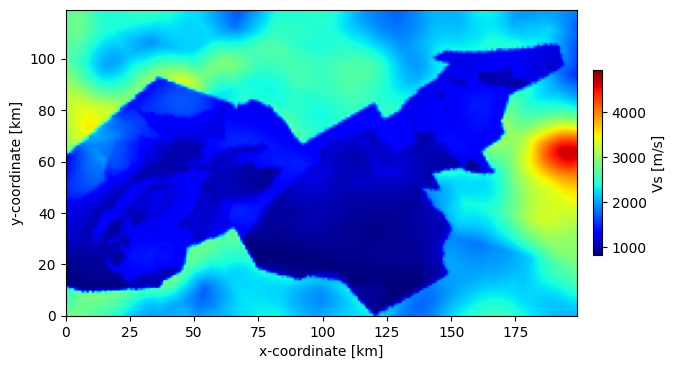

Figure saved in: Example_3DVelocityModel/outputData/Figures/Vs_XY_DepthIndex_0.svg
Figure saved in: Example_3DVelocityModel/outputData/Figures/Vs_XY_DepthIndex_5.svg


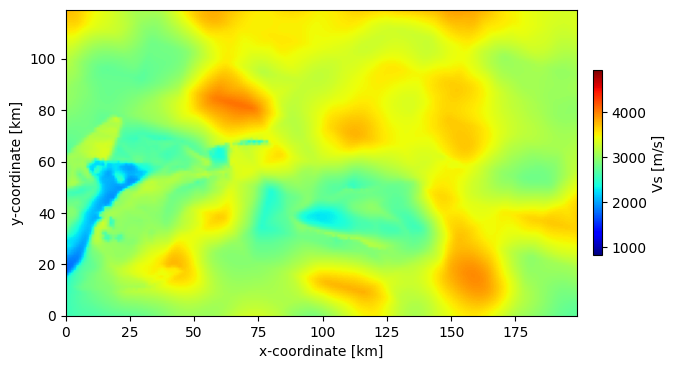

In [8]:
# Plot XY surface 
VelocityModel_utils.plot_surface_XY(
    binary_file_path=VM_binFile,
    variable_name='Vs',
    index=0,
    num_x=len(X),
    num_y=len(Y),
    num_z=len(Z), 
    variable_names=['Vp', 'Vs', 'Rho'],
    output_folder=output_folder_Fig,
    x_coords = coordinates[:, 0],
    y_coords = coordinates[:, 1],
    z_coords = coordinates[:, 2],
    display=True)

VelocityModel_utils.plot_surface_XY(
    binary_file_path=VM_binFile,
    variable_name='Vs',
    index=5,
    num_x=len(X),
    num_y=len(Y),
    num_z=len(Z), 
    variable_names=['Vp', 'Vs', 'Rho'],
    output_folder=output_folder_Fig,
    x_coords = coordinates[:, 0],
    y_coords = coordinates[:, 1],
    z_coords = coordinates[:, 2])

Figure saved in: Example_3DVelocityModel/outputData/Figures/Vp_XZ_ycoordIndex_10.svg


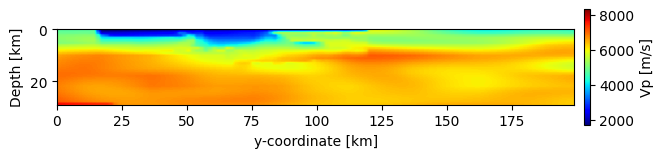

In [9]:
# Plot XZ or YZ surface 
VelocityModel_utils.plot_surface_XZorYZ(
    binary_file_path=VM_binFile,
    variable_name='Vp',
    index=10, 
    num_x=len(X), 
    num_y=len(Y), 
    num_z=len(Z), 
    variable_names=['Vp', 'Vs', 'Rho'], 
    plane_type='XZ',
    output_folder=output_folder_Fig,
    x_coords = coordinates[:, 0],
    y_coords = coordinates[:, 1],
    z_coords = coordinates[:, 2])